# 팀5 생산흐름 · 납기지연 예측 — Keras 딥러닝 이진분류 + 하이퍼파라미터 실험

**흐름:** 데이터 → 목표변수 0/1 → 누출 변수 제거 → 전처리 → Keras 모델 (**sigmoid + binary_crossentropy**) → 하이퍼파라미터 실험 → **혼동행렬**

### 와인 노트북(다중분류)과 달라지는 부분

| 항목 | 레드와인 (quality 3~8) | 팀3 (납기지연 Y/N) |
|---|---|---|
| 문제 유형 | 다중분류 | **이진분류** |
| 정답 y | `to_categorical` 원핫 | **0/1 그대로** |
| 출력층 | `Dense(10, activation='softmax')` | **`Dense(1, activation='sigmoid')`** |
| 손실함수 | `categorical_crossentropy` | **`binary_crossentropy`** |
| 예측 → 클래스 | `np.argmax(prob)` | **`prob >= 0.5`** (임계값) |

> 그림 라벨은 Colab 한글 폰트 문제를 피하려고 영어로 씁니다. 그림은 `figs/` 폴더에 저장되니 PPT에 바로 쓰면 됩니다.

## 1. 라이브러리 + 난수 고정

In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import AUC, Precision, Recall

SEED = 42
tf.keras.utils.set_random_seed(SEED)   # python·numpy·tensorflow 난수 고정 → 같은 설정이면 같은 결과
os.makedirs('figs', exist_ok=True)     # 발표용 그림 저장 폴더
print('TensorFlow', tf.__version__)

TensorFlow 2.22.0-rc0


## 2. 데이터 불러오기

In [22]:
URL = 'https://raw.githubusercontent.com/StillWork/capstone2610/main/team3_flow.csv'
df_raw = pd.read_csv(URL, encoding='utf-8-sig')   # utf-8-sig: 첫 열 이름에 BOM이 붙는 것 방지

# GitHub에서 안 받아지면 위 2줄을 지우고 아래 주석을 풀어 직접 업로드
# from google.colab import files
# up = files.upload()
# df_raw = pd.read_csv(list(up.keys())[0], encoding='utf-8-sig')

print('데이터 크기:', df_raw.shape)
df_raw.head()

데이터 크기: (1600, 26)


,record_id,lot_start_time,shift,line_id,product_family,order_priority,planned_qty,actual_qty,available_operators,changeover_min,...,wait_before_d_min,wip_start_qty,wip_end_qty,equipment_stop_min,material_wait_min,planned_lead_time_min,actual_lead_time_min,bottleneck_station,on_time_completion_flag,schedule_delay_min
0,FL-00001,2026-07-01 00:00:00,Day,L1,PF1,NORMAL,175,175,10,22.0,...,0.9,53,53,0.0,0.0,198.4,225.5,B,N,27.1
1,FL-00002,2026-07-01 01:30:00,Night,L1,PF2,NORMAL,186,186,7,0.0,...,5.8,50,50,0.0,0.0,214.6,260.7,C,N,46.1
2,FL-00003,2026-07-01 03:00:00,Day,L2,PF2,NORMAL,117,117,9,0.0,...,9.3,45,45,0.0,0.0,200.4,239.5,B,N,39.0
3,FL-00004,2026-07-01 04:30:00,Night,L1,PF2,NORMAL,129,129,10,0.0,...,0.1,44,44,34.5,0.0,221.1,266.9,B,N,45.8
4,FL-00005,2026-07-01 06:00:00,Day,L2,PF1,URGENT,166,166,9,0.0,...,7.8,29,29,0.0,0.0,191.6,200.6,B,N,9.0


In [23]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   record_id                1600 non-null   object 
 1   lot_start_time           1600 non-null   object 
 2   shift                    1600 non-null   object 
 3   line_id                  1600 non-null   object 
 4   product_family           1600 non-null   object 
 5   order_priority           1600 non-null   object 
 6   planned_qty              1600 non-null   int64  
 7   actual_qty               1600 non-null   int64  
 8   available_operators      1600 non-null   int64  
 9   changeover_min           1600 non-null   float64
 10  station_a_cycle_sec      1600 non-null   float64
 11  station_b_cycle_sec      1600 non-null   float64
 12  station_c_cycle_sec      1590 non-null   float64
 13  station_d_cycle_sec      1600 non-null   float64
 14  wait_before_b_min       

In [24]:
df_raw.describe()

,planned_qty,actual_qty,available_operators,changeover_min,station_a_cycle_sec,station_b_cycle_sec,station_c_cycle_sec,station_d_cycle_sec,wait_before_b_min,wait_before_c_min,wait_before_d_min,wip_start_qty,wip_end_qty,equipment_stop_min,material_wait_min,planned_lead_time_min,actual_lead_time_min,schedule_delay_min
count,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1590.000000,1600.000000,1600.000000,1584.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000,1600.000000
mean,179.140000,173.751875,8.561875,5.081312,45.306313,48.955688,48.657799,43.084625,13.140125,11.943939,5.856125,37.315000,42.703125,3.228813,2.423687,209.353438,248.115563,38.970813
std,31.553152,29.323949,1.484520,10.316761,3.616248,4.222961,5.603302,2.975666,7.755882,8.159158,4.095024,13.344927,20.392551,7.949260,7.128517,18.329778,28.917493,21.956569
min,100.000000,100.000000,5.000000,0.000000,34.300000,34.900000,33.500000,32.900000,0.000000,0.000000,0.000000,5.000000,5.000000,0.000000,0.000000,149.400000,164.300000,0.000000
25%,157.000000,154.000000,8.000000,0.000000,42.800000,46.100000,44.600000,41.100000,7.600000,6.200000,2.775000,28.000000,30.750000,0.000000,0.000000,197.175000,226.900000,23.175000
50%,179.000000,174.000000,9.000000,0.000000,45.200000,48.900000,48.300000,43.100000,12.200000,10.900000,5.600000,38.000000,40.000000,0.000000,0.000000,209.450000,247.250000,37.300000
75%,201.000000,194.000000,10.000000,0.000000,47.800000,51.700000,52.700000,45.000000,18.200000,16.700000,8.325000,46.000000,51.000000,0.000000,0.000000,221.900000,266.700000,52.500000
max,270.000000,270.000000,12.000000,42.600000,55.900000,67.200000,66.000000,53.800000,38.600000,44.800000,23.800000,83.000000,178.000000,49.200000,46.200000,279.500000,340.800000,132.800000


## 3. 목표변수 y — 0/1로 바꾸기

`on_time_completion_flag` 가 **N(납기지연) → 1**, **Y(정시완료) → 0**. 팀3 기존 노트북과 같은 정의입니다.

In [25]:
df = df_raw.copy()
df['target'] = (df['on_time_completion_flag'] == 'N').astype(int)   # 1 = 납기지연, 0 = 정시완료

print(df['target'].value_counts())
print('지연 비율: {:.1%}'.format(df['target'].mean()))

target
1    1337
0     263
Name: count, dtype: int64
지연 비율: 83.6%


> ⚠️ **지연(1)이 약 84%** 입니다. 모델이 전부 '지연'이라고 찍기만 해도 정확도가 0.84 나옵니다.
> 그래서 accuracy만 보지 않고 **AUC · precision · recall · 혼동행렬**을 함께 봅니다.

## 4. 입력변수 고르기 — 데이터 누출 막기

판단 시점은 **교대 시작 전**입니다. 계획수량·제품군·작업자 수·교체계획은 알지만, 실제 사이클타임·대기시간·완료수량은 아직 모릅니다.

| 사용 금지 변수 | 이유 |
|---|---|
| `schedule_delay_min` | 지연(분) = 정답을 계산한 근거값. 가장 치명적인 누출 |
| `actual_lead_time_min`, `actual_qty`, `wip_end_qty` | 로트가 끝난 뒤에 생기는 값 |
| `bottleneck_station` | 공정이 진행된 뒤에야 알 수 있음 |
| `station_*_cycle_sec`, `wait_before_*_min`, `equipment_stop_min`, `material_wait_min` | 실제 진행 중에 측정되는 값 |
| `record_id`, `lot_start_time` | 식별번호·시각 |

> 결측치는 `station_c_cycle_sec`, `wait_before_c_min` 에만 있는데 둘 다 입력에서 빠지므로 따로 채우지 않습니다.

In [26]:
CAT = ['shift', 'line_id', 'product_family', 'order_priority']                    # 범주형 → 원핫
NUM = ['planned_qty', 'available_operators', 'changeover_min', 'wip_start_qty',
       'planned_lead_time_min']                                                   # 수치형 → 스케일링

print('범주형', len(CAT), '개:', CAT)
print('수치형', len(NUM), '개:', NUM)

범주형 4 개: ['shift', 'line_id', 'product_family', 'order_priority']
수치형 5 개: ['planned_qty', 'available_operators', 'changeover_min', 'wip_start_qty', 'planned_lead_time_min']


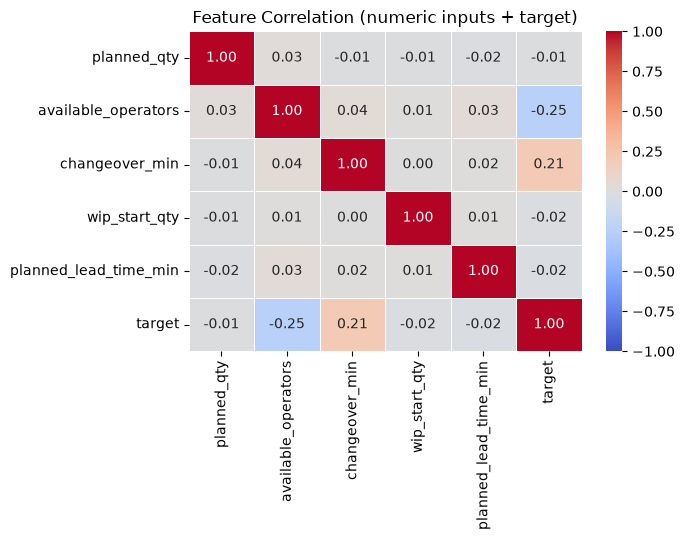

In [27]:
# 수치형 입력과 target의 상관관계 (와인 노트북의 히트맵과 같은 방식)
corr = df[NUM + ['target']].corr(method='pearson')

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation (numeric inputs + target)')
plt.tight_layout()
plt.savefig('figs/01_corr_heatmap.png', dpi=150)
plt.show()

## 5. 전처리 — 원핫인코딩 → 분리(학습 60 / 검증 20 / 평가 20) → 스케일링

- **검증(val)**: 하이퍼파라미터를 고를 때 사용
- **평가(test)**: 마지막에 최종 모델로 딱 한 번만 사용 (혼동행렬)
- `stratify=y`: 세 데이터셋의 지연 비율을 똑같이 맞춤
- 스케일러는 **학습 데이터로만 fit** (검증·평가는 transform만)

In [28]:
X = pd.concat([df[NUM], pd.get_dummies(df[CAT])], axis=1).astype('float32')
y = df['target'].values
FEATURES = X.columns.tolist()

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED)   # 0.8 x 0.25 = 0.2

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print('입력 특성 수:', len(FEATURES))
print('X_train', X_train.shape, '| 지연비율 {:.3f}'.format(y_train.mean()))
print('X_val  ', X_val.shape, '| 지연비율 {:.3f}'.format(y_val.mean()))
print('X_test ', X_test.shape, '| 지연비율 {:.3f}'.format(y_test.mean()))

입력 특성 수: 15
X_train (960, 15) | 지연비율 0.836
X_val   (320, 15) | 지연비율 0.834
X_test  (320, 15) | 지연비율 0.834


## 6. 모델 만드는 함수

하이퍼파라미터를 인자로 받아서 모델을 만들어 주는 함수입니다. 실험할 때는 인자만 바꿉니다.

- 은닉층: `Dense(units, activation='relu')` + `Dropout`
- **출력층: `Dense(1, activation='sigmoid')`** → 0~1 사이 확률 = '지연일 확률'
- **손실: `binary_crossentropy`**

In [29]:
def build_model(hidden=(32, 16, 8), dropout=0.3, lr=0.001):
    inputs = Input(shape=(X_train.shape[1],))
    x = inputs
    for units in hidden:
        x = Dense(units, activation='relu')(x)
        if dropout > 0:
            x = Dropout(dropout)(x)
    outputs = Dense(1, activation='sigmoid')(x)        # 이진분류: 노드 1개 + sigmoid

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='binary_crossentropy',                    # 이진분류 손실
        metrics=['accuracy', AUC(name='auc'),
                 Precision(name='precision'), Recall(name='recall')]
    )
    return model

build_model().summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_53 (Dense)                │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_54 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_55 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_56 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

## 7. 실험 실행 · 기록 함수

`run_experiment()` 한 번 = 모델 하나 학습 + 결과표(`results`)에 한 줄 기록.
같은 이름으로 다시 돌리면 이전 기록을 덮어씁니다.

- `class_weight`: 소수 클래스(정시완료 0)의 오답에 손실 가중치를 더 줌 → E6에서 사용
- `val_bal_acc@0.5`: 임계값 0.5에서 **두 클래스 recall의 평균**. **0.5에 가까우면 한쪽으로만 찍는 모델**입니다 (예: 전부 지연)

In [ ]:
results = []    # 실험 결과 표
trained = {}    # 실험이름 -> (model, history)

# 클래스 가중치: n / (2 x 클래스 개수) → 드문 정시완료(0)의 오답에 더 큰 벌점
counts = np.bincount(y_train)
CW = {0: len(y_train) / (2 * counts[0]), 1: len(y_train) / (2 * counts[1])}
print('class_weight:', {k: round(v, 3) for k, v in CW.items()})


def run_experiment(name, hidden=(32, 16, 8), dropout=0.3, lr=0.001,
                   batch_size=32, epochs=100, early_stop=False, class_weight=None,
                   es_monitor='val_loss', patience=10, verbose=0):
    tf.keras.utils.set_random_seed(SEED)               # 실험마다 같은 출발점
    model = build_model(hidden, dropout, lr)
    callbacks = []
    if early_stop:
        mode = 'max' if 'auc' in es_monitor else 'min'
        callbacks.append(EarlyStopping(monitor=es_monitor, mode=mode, patience=patience,
                                       restore_best_weights=True))

    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size,
                        class_weight=class_weight,
                        callbacks=callbacks, verbose=verbose)

    val = model.evaluate(X_val, y_val, verbose=0, return_dict=True)
    val_prob = model.predict(X_val, verbose=0).ravel()
    val_bacc = balanced_accuracy_score(y_val, (val_prob >= 0.5).astype(int))

    results[:] = [r for r in results if r['name'] != name]
    results.append({
        'name': name, 'hidden': str(hidden), 'dropout': dropout, 'lr': lr,
        'batch': batch_size, 'class_weight': 'balanced' if class_weight else '-',
        'early_stop': es_monitor if early_stop else '-',
        'epochs_run': len(history.history['loss']),
        'val_loss': round(val['loss'], 4), 'val_acc': round(val['accuracy'], 4),
        'val_auc': round(val['auc'], 4), 'val_precision': round(val['precision'], 4),
        'val_recall': round(val['recall'], 4), 'val_bal_acc@0.5': round(val_bacc, 4),
    })
    trained[name] = (model, history)
    print('[{}] val_loss={:.4f}  val_auc={:.4f}  val_bal_acc@0.5={:.4f}  ({} epochs)'.format(
        name, val['loss'], val['auc'], val_bacc, len(history.history['loss'])))
    return model, history


def plot_history(name):
    h = trained[name][1].history
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(h['loss'], label='Train Loss')
    plt.plot(h['val_loss'], label='Val Loss')
    plt.title(name + ' - Loss'); plt.xlabel('Epochs'); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(h['accuracy'], label='Train Acc')
    plt.plot(h['val_accuracy'], label='Val Acc')
    plt.title(name + ' - Accuracy'); plt.xlabel('Epochs'); plt.legend()
    plt.tight_layout()
    plt.savefig('figs/' + name + '_history.png', dpi=150)
    plt.show()


def compare_curves(names, metric='val_loss', title=None):
    plt.figure(figsize=(7, 4))
    for n in names:
        plt.plot(trained[n][1].history[metric], label=n)
    title = title or metric
    plt.title(title); plt.xlabel('Epochs'); plt.ylabel(metric); plt.legend()
    plt.tight_layout()
    plt.savefig('figs/compare_' + title.replace(' ', '_') + '.png', dpi=150)
    plt.show()

class_weight: {0: np.float64(3.057), 1: np.float64(0.598)}


## 8. 실험 0 — 베이스라인

은닉층 32-16-8, Dropout 0.3, Adam lr=0.001, batch 32, epochs 100

[E0_baseline] val_loss=0.3893  val_auc=0.8018  val_bal_acc@0.5=0.6077  (100 epochs)


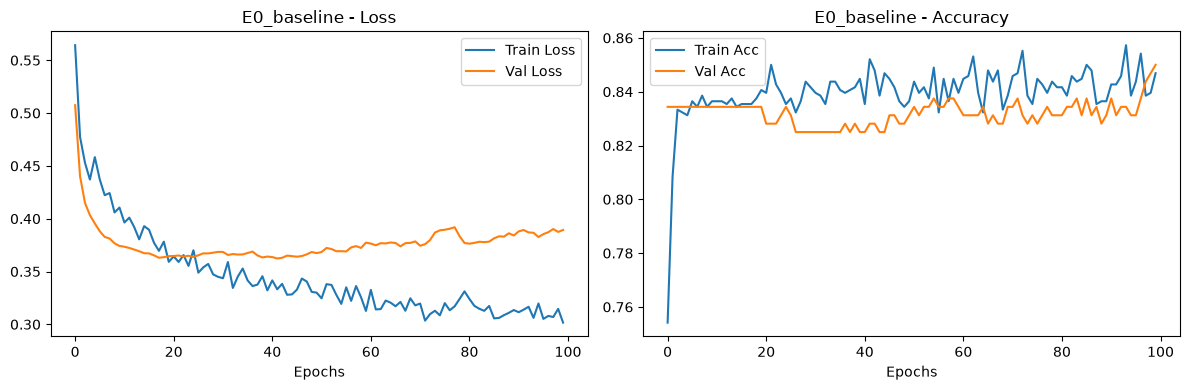

In [31]:
run_experiment('E0_baseline')
plot_history('E0_baseline')

## 9. 하이퍼파라미터 실험 — 한 번에 하나만 바꾸기

나머지는 베이스라인 그대로 두고 **하나만** 바꿔야 무엇이 효과를 냈는지 말할 수 있습니다.

| 실험 | 바꾸는 것 | 후보 |
|---|---|---|
| E1 | 은닉층 구조 | (8,) / (16, 8) / (64, 32, 16) |
| E2 | Dropout | 0.0 / 0.2 / 0.5 |
| E3 | 학습률 lr | 0.01 / 0.0001 |
| E4 | 배치 크기 | 16 / 64 |
| E5 | 에폭 · 조기종료 | 300 / 300 + EarlyStopping |
| E6 | 클래스 불균형 대응 | class_weight 적용 |
| E7 | **최종 조합** | E1~E6에서 좋았던 설정을 합침 |

후보 값은 자유롭게 바꾸거나 추가해도 됩니다.

### E1. 은닉층 구조 (층 수 · 노드 수)

[E1_hidden_8] val_loss=0.3616  val_auc=0.8035  val_bal_acc@0.5=0.5529  (100 epochs)
[E1_hidden_16-8] val_loss=0.3718  val_auc=0.8019  val_bal_acc@0.5=0.5321  (100 epochs)
[E1_hidden_64-32-16] val_loss=0.4534  val_auc=0.7755  val_bal_acc@0.5=0.6134  (100 epochs)


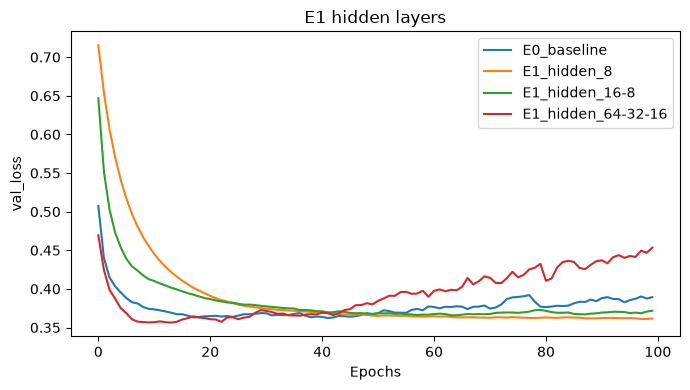

In [32]:
E1 = []
for h in [(8,), (16, 8), (64, 32, 16)]:
    name = 'E1_hidden_' + '-'.join(map(str, h))
    run_experiment(name, hidden=h)
    E1.append(name)

compare_curves(['E0_baseline'] + E1, 'val_loss', 'E1 hidden layers')

### E2. Dropout 비율

[E2_dropout_0.0] val_loss=0.6819  val_auc=0.7134  val_bal_acc@0.5=0.6005  (100 epochs)
[E2_dropout_0.2] val_loss=0.4252  val_auc=0.7879  val_bal_acc@0.5=0.6211  (100 epochs)
[E2_dropout_0.5] val_loss=0.3686  val_auc=0.8068  val_bal_acc@0.5=0.5000  (100 epochs)


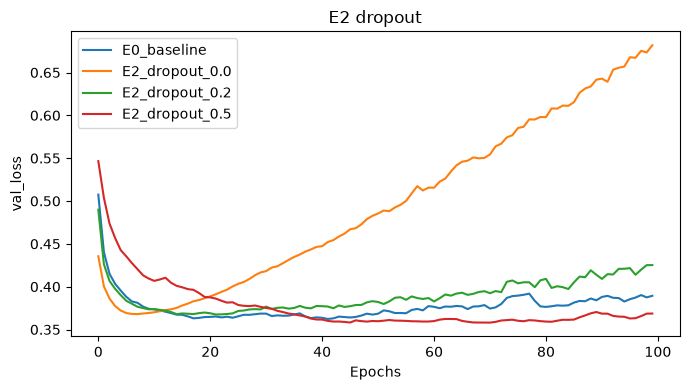

In [33]:
E2 = []
for d in [0.0, 0.2, 0.5]:
    name = 'E2_dropout_' + str(d)
    run_experiment(name, dropout=d)
    E2.append(name)

compare_curves(['E0_baseline'] + E2, 'val_loss', 'E2 dropout')

### E3. 학습률 (learning rate)

[E3_lr_0.01] val_loss=0.5397  val_auc=0.7582  val_bal_acc@0.5=0.5416  (100 epochs)
[E3_lr_0.0001] val_loss=0.3747  val_auc=0.7860  val_bal_acc@0.5=0.5000  (100 epochs)


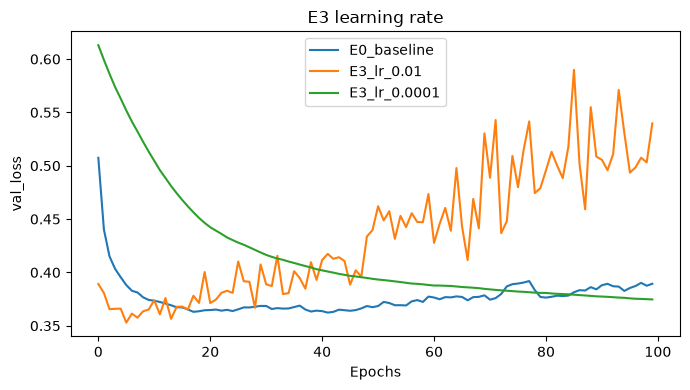

In [34]:
E3 = []
for lr in [0.01, 0.0001]:
    name = 'E3_lr_' + str(lr)
    run_experiment(name, lr=lr)
    E3.append(name)

compare_curves(['E0_baseline'] + E3, 'val_loss', 'E3 learning rate')

### E4. 배치 크기

[E4_batch_16] val_loss=0.4301  val_auc=0.7856  val_bal_acc@0.5=0.5681  (100 epochs)
[E4_batch_64] val_loss=0.3771  val_auc=0.8039  val_bal_acc@0.5=0.5775  (100 epochs)


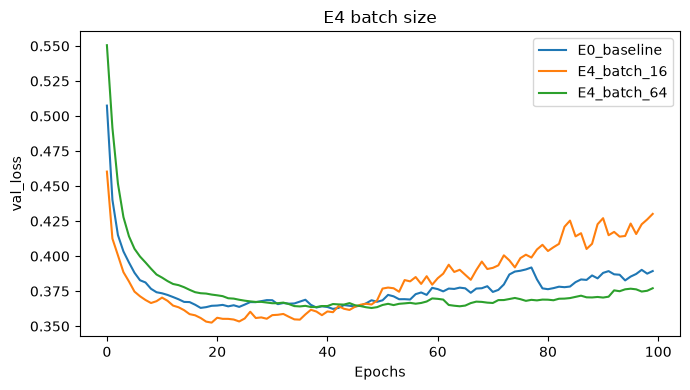

In [35]:
E4 = []
for b in [16, 64]:
    name = 'E4_batch_' + str(b)
    run_experiment(name, batch_size=b)
    E4.append(name)

compare_curves(['E0_baseline'] + E4, 'val_loss', 'E4 batch size')

### E5. 에폭 수 · 조기종료(EarlyStopping)

에폭을 크게 늘리면 학습 loss는 계속 내려가도 val loss는 다시 올라갈 수 있습니다(과적합).
EarlyStopping은 val loss가 10에폭 동안 좋아지지 않으면 멈추고, 가장 좋았던 가중치로 되돌립니다.

[E5_epochs300] val_loss=0.5664  val_auc=0.7702  val_bal_acc@0.5=0.6230  (300 epochs)
[E5_epochs300_es] val_loss=0.3630  val_auc=0.8013  val_bal_acc@0.5=0.5000  (28 epochs)


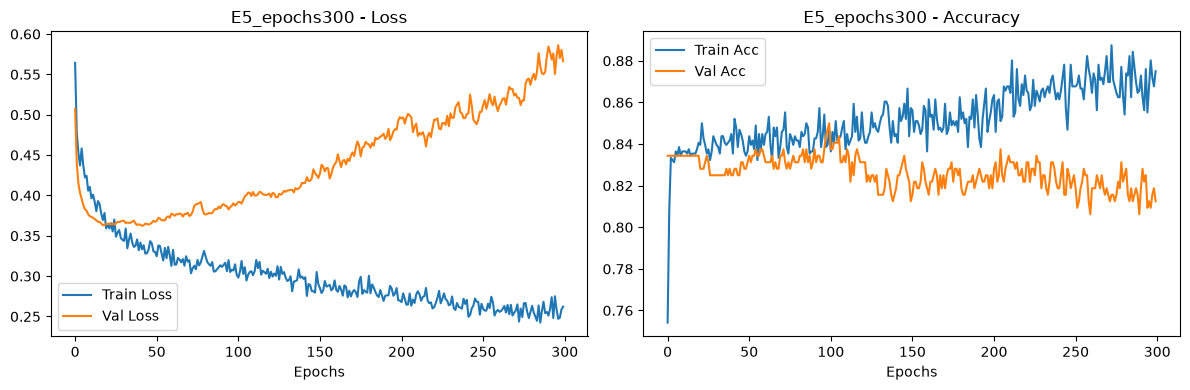

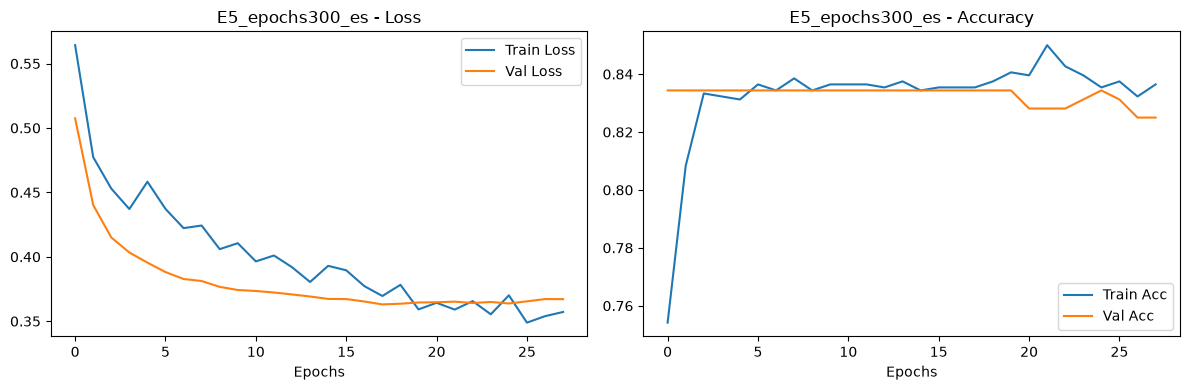

In [36]:
run_experiment('E5_epochs300', epochs=300)
run_experiment('E5_epochs300_es', epochs=300, early_stop=True)

plot_history('E5_epochs300')
plot_history('E5_epochs300_es')

### E6. 클래스 불균형 대응 — class_weight

지연이 84%라 모델은 '전부 지연'으로 찍기만 해도 손실이 꽤 낮아집니다.
`class_weight`로 **정시완료(0)를 틀리면 약 3배 벌점**을 주면, 모델이 정시완료도 구분하려고 학습합니다.

> 손실 가중치가 바뀌면 출력 확률이 0.5 근처로 내려오므로, `val_loss`(가중치 없음)는 오히려 높게 나올 수 있습니다. 비교는 `val_auc`와 `val_bal_acc@0.5`로 합니다.

In [37]:
run_experiment('E6_classweight', class_weight=CW)

pd.DataFrame(results).set_index('name').loc[
    ['E0_baseline', 'E6_classweight'],
    ['class_weight', 'val_loss', 'val_auc', 'val_recall', 'val_bal_acc@0.5']]

[E6_classweight] val_loss=0.5245  val_auc=0.8009  val_bal_acc@0.5=0.6975  (100 epochs)


,class_weight,val_loss,val_auc,val_recall,val_bal_acc@0.5
name,,,,,
E0_baseline,-,0.3893,0.8018,0.9700,0.6077
E6_classweight,balanced,0.5245,0.8009,0.6592,0.6975


### E7. 최종 조합 — 좋았던 설정 합치기

- Dropout **0.5** (E2) + 넉넉한 에폭 300 + **EarlyStopping** (E5) + **class_weight** (E6)
- class_weight를 쓰면 `val_loss`가 처음부터 오를 수 있어서, 조기종료 기준은 **`val_auc`** (patience 20)로 둡니다.
- 작은 모델 (8,)이 나았던 E1 결과도 함께 비교합니다.

[E7_drop0.5_es] val_loss=0.3590  val_auc=0.8166  val_bal_acc@0.5=0.5000  (102 epochs)
[E7_drop0.5_es_cw] val_loss=0.5023  val_auc=0.8243  val_bal_acc@0.5=0.7487  (99 epochs)
[E7_h8_drop0.5_es_cw] val_loss=0.4922  val_auc=0.8179  val_bal_acc@0.5=0.7143  (110 epochs)


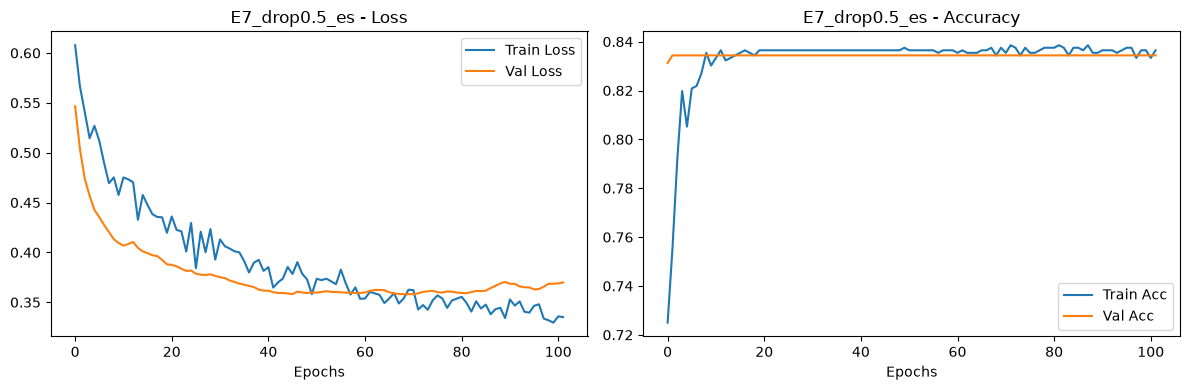

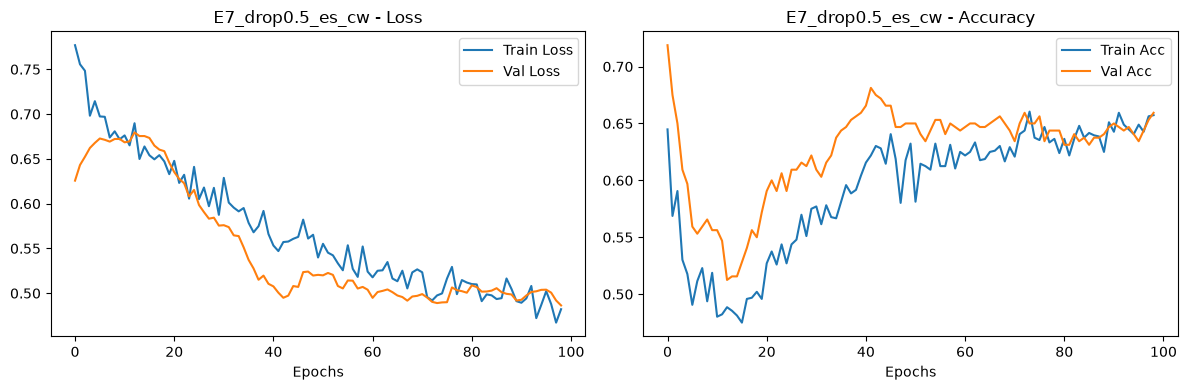

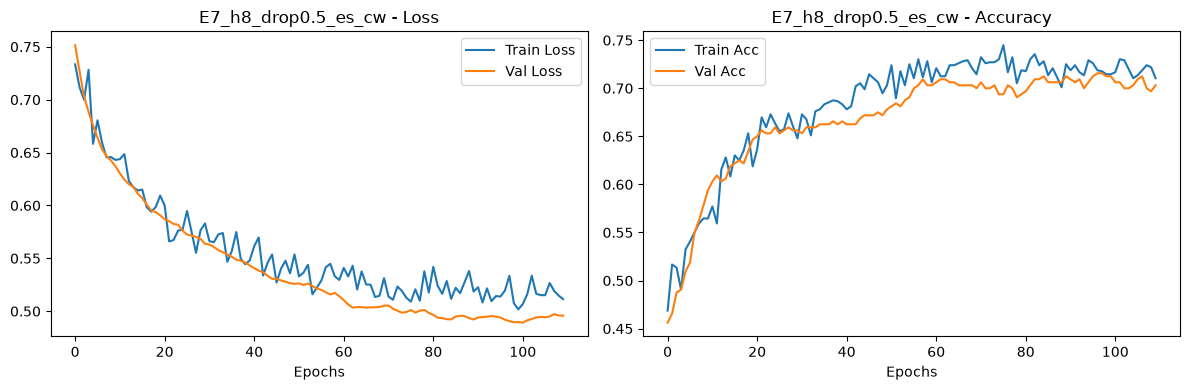

In [38]:
E7 = []
for name, h, cw in [('E7_drop0.5_es', (32, 16, 8), None),
                     ('E7_drop0.5_es_cw', (32, 16, 8), CW),
                     ('E7_h8_drop0.5_es_cw', (8,), CW)]:
    run_experiment(name, hidden=h, dropout=0.5, epochs=300, early_stop=True,
                   es_monitor='val_auc', patience=20, class_weight=cw)
    E7.append(name)

for n in E7:
    plot_history(n)

## 10. 실험 결과 비교표

**선택 기준: `val_auc`** (임계값과 상관없는 지표). 비슷하면 `val_loss`가 낮은 쪽.

- `val_acc`는 대부분 0.83~0.84 → '전부 지연' 정확도(0.834)와 거의 같아서 **비교 기준으로 쓸 수 없음**
- `val_bal_acc@0.5`가 0.5 근처인 모델은 0.5 기준에서 한쪽으로만 찍고 있다는 뜻 → 12절에서 임계값으로 보정

In [39]:
res = pd.DataFrame(results).set_index('name')
res.to_csv('figs/experiment_results.csv', encoding='utf-8-sig')   # PPT 표 만들 때 사용
res.sort_values('val_auc', ascending=False)

,hidden,dropout,lr,batch,class_weight,early_stop,epochs_run,val_loss,val_acc,val_auc,val_precision,val_recall,val_bal_acc@0.5
name,,,,,,,,,,,,,
E7_drop0.5_es_cw,"(32, 16, 8)",0.5,0.0010,32,balanced,val_auc,99,0.5023,0.6438,0.8243,0.9693,0.5918,0.7487
E7_h8_drop0.5_es_cw,"(8,)",0.5,0.0010,32,balanced,val_auc,110,0.4922,0.7125,0.8179,0.9268,0.7116,0.7143
E7_drop0.5_es,"(32, 16, 8)",0.5,0.0010,32,-,val_auc,102,0.3590,0.8344,0.8166,0.8344,1.0000,0.5000
E2_dropout_0.5,"(32, 16, 8)",0.5,0.0010,32,-,-,100,0.3686,0.8344,0.8068,0.8344,1.0000,0.5000
E4_batch_64,"(32, 16, 8)",0.3,0.0010,64,-,-,100,0.3771,0.8375,0.8039,0.8571,0.9663,0.5775
E1_hidden_8,"(8,)",0.3,0.0010,32,-,-,100,0.3616,0.8344,0.8035,0.8497,0.9738,0.5529
E1_hidden_16-8,"(16, 8)",0.3,0.0010,32,-,-,100,0.3718,0.8375,0.8019,0.8435,0.9888,0.5321
E0_baseline,"(32, 16, 8)",0.3,0.0010,32,-,-,100,0.3893,0.8500,0.8018,0.8662,0.9700,0.6077
E5_epochs300_es,"(32, 16, 8)",0.3,0.0010,32,-,val_loss,28,0.3630,0.8344,0.8013,0.8344,1.0000,0.5000


## 11. 최종 모델 — test 데이터 평가 + 혼동행렬 (임계값 0.5 그대로)

`sigmoid` 출력은 '지연일 확률'입니다. 우선 기본값 **0.5 이상이면 지연(1)** 으로 판정해 봅니다.

In [40]:
BEST = res['val_auc'].idxmax()      # 직접 고르려면 예: BEST = 'E2_dropout_0.2'
best_model = trained[BEST][0]
print('최종 모델:', BEST)
print(res.loc[BEST])

test = best_model.evaluate(X_test, y_test, verbose=0, return_dict=True)
print('\n[TEST] loss={:.4f}  acc={:.4f}  auc={:.4f}'.format(test['loss'], test['accuracy'], test['auc']))
print('참고: 전부 지연이라고 찍었을 때 정확도 = {:.4f}'.format(y_test.mean()))

최종 모델: E7_drop0.5_es_cw
hidden             (32, 16, 8)
dropout                    0.5
lr                       0.001
batch                       32
class_weight          balanced
early_stop             val_auc
epochs_run                  99
val_loss                0.5023
val_acc                 0.6438
val_auc                 0.8243
val_precision           0.9693
val_recall              0.5918
val_bal_acc@0.5         0.7487
Name: E7_drop0.5_es_cw, dtype: object

[TEST] loss=0.5788  acc=0.6313  auc=0.7934
참고: 전부 지연이라고 찍었을 때 정확도 = 0.8344


=== Classification Report (threshold 0.5) ===
              precision    recall  f1-score   support

 On-time (0)       0.30      0.89      0.44        53
   Delay (1)       0.96      0.58      0.72       267

    accuracy                           0.63       320
   macro avg       0.63      0.73      0.58       320
weighted avg       0.85      0.63      0.68       320

balanced accuracy: 0.7337


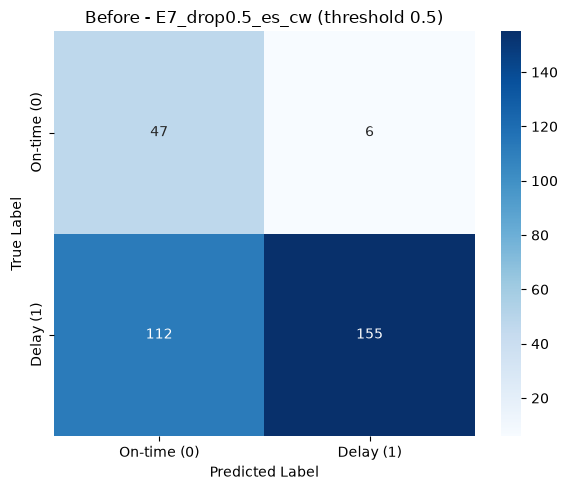

In [41]:
THRESHOLD = 0.5
y_prob = best_model.predict(X_test, verbose=0).ravel()   # 지연일 확률 (0~1)
y_pred = (y_prob >= THRESHOLD).astype(int)

labels = ['On-time (0)', 'Delay (1)']
print('=== Classification Report (threshold 0.5) ===')
print(classification_report(y_test, y_pred, target_names=labels, zero_division=0))
print('balanced accuracy: {:.4f}'.format(balanced_accuracy_score(y_test, y_pred)))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Before - ' + BEST + ' (threshold 0.5)')
plt.xlabel('Predicted Label'); plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('figs/confusion_matrix_th0.5.png', dpi=150)
plt.show()

### 왜 이런 결과가 나왔나 — 예측 확률 분포

두 클래스의 확률 분포가 **어느 정도 갈라져 있다면** AUC는 괜찮게 나옵니다. 그런데 분포 전체가 0.5보다 오른쪽에 있으면, 0.5로 자를 때 전부 '지연'이 됩니다.

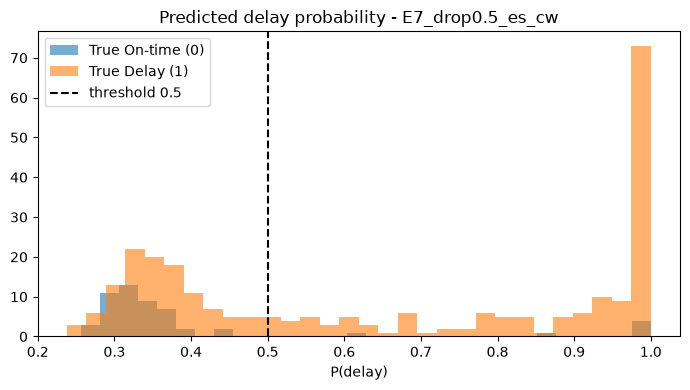

In [42]:
plt.figure(figsize=(7, 4))
plt.hist(y_prob[y_test == 0], bins=30, alpha=0.6, label='True On-time (0)')
plt.hist(y_prob[y_test == 1], bins=30, alpha=0.6, label='True Delay (1)')
plt.axvline(0.5, color='k', ls='--', label='threshold 0.5')
plt.title('Predicted delay probability - ' + BEST); plt.xlabel('P(delay)'); plt.legend()
plt.tight_layout()
plt.savefig('figs/prob_hist.png', dpi=150)
plt.show()

## 12. 임계값 정하기 — val 데이터로 고르고, test에는 한 번만 적용

임계값도 하이퍼파라미터입니다. **test를 보고 고르면 반칙**(test 정보가 모델 선택에 새어 들어감)이므로 val 데이터에서 고릅니다.

기준: **balanced accuracy** = (정시완료 recall + 지연 recall) / 2 가 가장 높은 임계값

val 기준 최적 임계값: 0.49


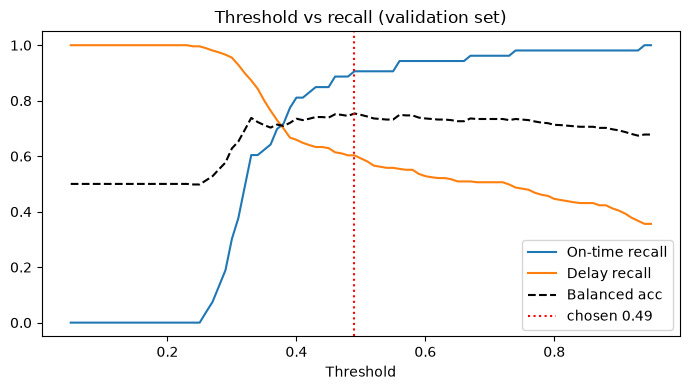

,threshold,TN,FP,FN,TP,ontime_recall,delay_recall,bal_acc
25,0.30,16,37,12,255,0.302,0.955,0.628
35,0.40,43,10,91,176,0.811,0.659,0.735
44,0.49,48,5,106,161,0.906,0.603,0.754
45,0.50,48,5,109,158,0.906,0.592,0.749
55,0.60,50,3,126,141,0.943,0.528,0.736
65,0.70,51,2,132,135,0.962,0.506,0.734
75,0.80,52,1,148,119,0.981,0.446,0.713


In [43]:
y_val_prob = best_model.predict(X_val, verbose=0).ravel()

rows = []
for th in np.arange(0.05, 0.96, 0.01):
    p = (y_val_prob >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, p, labels=[0, 1]).ravel()
    r0, r1 = tn / (tn + fp), tp / (tp + fn)
    rows.append({'threshold': round(th, 2), 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                 'ontime_recall': r0, 'delay_recall': r1, 'bal_acc': (r0 + r1) / 2})
th_tbl = pd.DataFrame(rows).round(3)
BEST_TH = float(th_tbl.loc[th_tbl['bal_acc'].idxmax(), 'threshold'])
print('val 기준 최적 임계값:', BEST_TH)

plt.figure(figsize=(7, 4))
plt.plot(th_tbl['threshold'], th_tbl['ontime_recall'], label='On-time recall')
plt.plot(th_tbl['threshold'], th_tbl['delay_recall'], label='Delay recall')
plt.plot(th_tbl['threshold'], th_tbl['bal_acc'], 'k--', label='Balanced acc')
plt.axvline(BEST_TH, color='r', ls=':', label='chosen ' + str(BEST_TH))
plt.title('Threshold vs recall (validation set)'); plt.xlabel('Threshold'); plt.legend()
plt.tight_layout()
plt.savefig('figs/threshold_val.png', dpi=150)
plt.show()

show = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, BEST_TH]
th_tbl[th_tbl['threshold'].isin(show)]

## 13. 최종 결과 — val에서 고른 임계값을 test에 적용 (After)

=== Classification Report (threshold 0.49) ===
              precision    recall  f1-score   support

 On-time (0)       0.30      0.89      0.45        53
   Delay (1)       0.96      0.59      0.73       267

    accuracy                           0.64       320
   macro avg       0.63      0.74      0.59       320
weighted avg       0.85      0.64      0.68       320

balanced accuracy: 0.5 기준 0.7337 -> 0.49 기준 0.7374


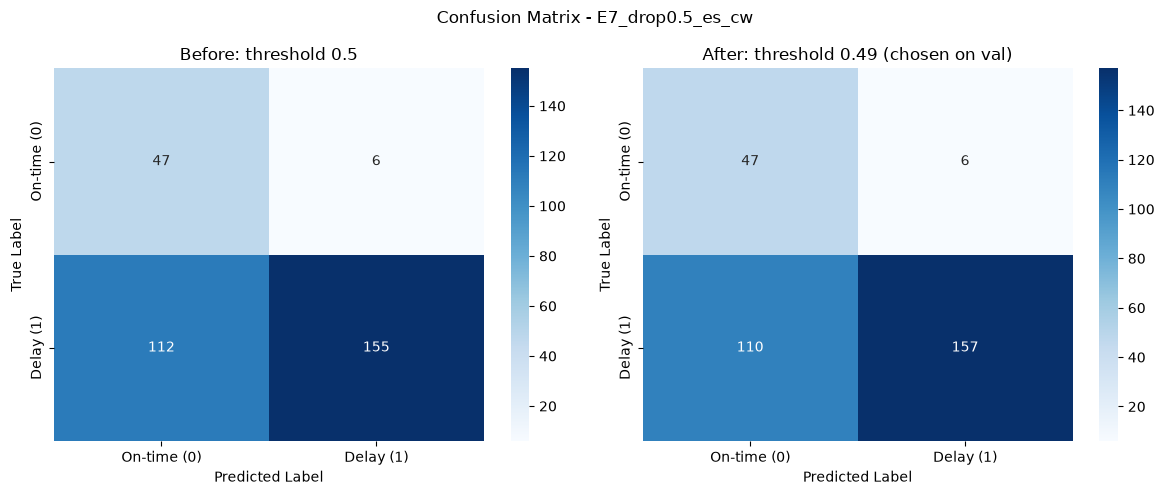

In [44]:
y_pred_t = (y_prob >= BEST_TH).astype(int)

print('=== Classification Report (threshold {}) ==='.format(BEST_TH))
print(classification_report(y_test, y_pred_t, target_names=labels, zero_division=0))
print('balanced accuracy: 0.5 기준 {:.4f} -> {} 기준 {:.4f}'.format(
    balanced_accuracy_score(y_test, y_pred), BEST_TH, balanced_accuracy_score(y_test, y_pred_t)))

cm_t = confusion_matrix(y_test, y_pred_t, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, m, t in [(axes[0], cm, 'Before: threshold 0.5'),
                 (axes[1], cm_t, 'After: threshold ' + str(BEST_TH) + ' (chosen on val)')]:
    sns.heatmap(m, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(t); ax.set_xlabel('Predicted Label'); ax.set_ylabel('True Label')
plt.suptitle('Confusion Matrix - ' + BEST)
plt.tight_layout()
plt.savefig('figs/confusion_matrix_before_after.png', dpi=150)
plt.show()

## 13-2. 기존 ML 모델과 비교 — 같은 test 데이터에서

딥러닝이 정말 나은지 보려면 **같은 분할 · 같은 입력 · 같은 규칙**으로 비교해야 합니다.

- 모델 설정은 팀3 기존 노트북(N04)과 동일: 로지스틱회귀 / 의사결정나무 / 랜덤포레스트, 모두 `class_weight='balanced'`
- 임계값은 모델마다 **val에서** balanced accuracy가 가장 높은 값을 고르고, test에는 한 번만 적용
- test의 정시완료가 53건뿐이라 0.01~0.02 차이는 우연일 수 있음

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

THS = np.round(np.arange(0.05, 0.96, 0.01), 2)
cmp_rows = []

def add_row(name, p_val, p_test):
    th = float(THS[np.argmax([balanced_accuracy_score(y_val, (p_val >= t).astype(int)) for t in THS])])
    pred = (p_test >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    cmp_rows.append({'model': name, 'threshold(val)': th,
                     'test_auc': round(roc_auc_score(y_test, p_test), 4),
                     'test_bal_acc': round(balanced_accuracy_score(y_test, pred), 4),
                     'test_acc': round((tn + tp) / len(y_test), 4),
                     'ontime_hit': f'{tn}/{tn + fp}', 'delay_hit': f'{tp}/{tp + fn}'})

add_row('Keras ' + BEST, y_val_prob, y_prob)

baselines = {
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'DecisionTree': DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                           class_weight='balanced', random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                           class_weight='balanced', random_state=42),
}
for name, m in baselines.items():
    m.fit(X_train, y_train)
    add_row(name, m.predict_proba(X_val)[:, 1], m.predict_proba(X_test)[:, 1])

cmp_tbl = pd.DataFrame(cmp_rows).set_index('model')
cmp_tbl.to_csv('figs/model_comparison.csv', encoding='utf-8-sig')
cmp_tbl

## 14. 정리 — 실행 후 직접 작성 (발표 슬라이드로 옮길 내용)

- **과적합:** E0에서 val loss 최저점 ___에폭, 이후 상승 → Dropout↑ · 작은 모델 · EarlyStopping으로 완화 (E2·E1·E5 근거)
- **0.5 기준의 함정:** 최종 모델이 test ___개 전부 '지연'으로 예측 → 정확도 0.834 = 전부 지연 기준선과 동일
- **해결:** class_weight (E6) + val에서 고른 임계값 ___ → 정시완료 ___/53개 탐지, balanced accuracy ___ → ___
- **최종 설정:** ___
- **한계:** 교대 시작 전 정보만 쓰므로 입력이 적다 (AUC 약 0.8) · 데이터 1,600건